# Исследование объявлений о продаже квартир

В вашем распоряжении данные сервиса Яндекс Недвижимость — архив объявлений о продаже квартир в Санкт-Петербурге и соседних населённых пунктах за несколько лет. Вам нужно научиться определять рыночную стоимость объектов недвижимости. Для этого проведите исследовательский анализ данных и установите параметры, влияющие на цену объектов. Это позволит построить автоматизированную систему: она отследит аномалии и мошенническую деятельность.

По каждой квартире на продажу доступны два вида данных. Первые вписаны пользователем, вторые — получены автоматически на основе картографических данных. Например, расстояние до центра, аэропорта и других объектов — эти данные автоматически получены из геосервисов. Количество парков и водоёмов также заполняется без участия пользователя.

## 1. Загрузка и первичный осмотр

In [1]:
from io import BytesIO
from pathlib import Path
from shutil import which
from subprocess import CalledProcessError, run

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

dataset_name = 'real_estate_data.csv'
paths = [Path(dataset_name), Path('/datasets') / dataset_name]
dataset_url = 'https://code.s3.yandex.net/datasets/real_estate_data.csv'
source = next((path for path in paths if path.is_file()), dataset_url)
try:
    curl = which('curl')
    if source == dataset_url and curl:
        download = run([curl, '-fsSL', '--max-time', '45', dataset_url],
                       capture_output=True, check=True)
        source = BytesIO(download.stdout)
    raw = pd.read_csv(source, sep='\t')
except (OSError, CalledProcessError, UnicodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as error:
    raise RuntimeError(f'Не удалось прочитать файл {dataset_name}.') from error

required = {
    'total_images', 'last_price', 'total_area', 'first_day_exposition', 'rooms',
    'ceiling_height', 'floors_total', 'living_area', 'floor', 'is_apartment',
    'studio', 'open_plan', 'kitchen_area', 'balcony', 'locality_name',
    'airports_nearest', 'cityCenters_nearest', 'parks_around3000',
    'parks_nearest', 'ponds_around3000', 'ponds_nearest', 'days_exposition',
}
if required.difference(raw.columns):
    raise ValueError(f'Нет ожидаемых столбцов: {sorted(required.difference(raw.columns))}')
display(raw.head())
raw.info()

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,13000000.0,108.0,2019-03-07T00:00:00,3,2.70,16.0,51.0,8,NaN,...,25.0,NaN,Санкт-Петербург,18863.0,16028.0,1.0,482.0,2.0,755.0,NaN
1,7,3350000.0,40.4,2018-12-04T00:00:00,1,NaN,11.0,18.6,1,NaN,...,11.0,2.0,посёлок Шушары,12817.0,18603.0,0.0,NaN,0.0,NaN,81.0
2,10,5196000.0,56.0,2015-08-20T00:00:00,2,NaN,5.0,34.3,4,NaN,...,8.3,0.0,Санкт-Петербург,21741.0,13933.0,1.0,90.0,2.0,574.0,558.0
3,0,64900000.0,159.0,2015-07-24T00:00:00,3,NaN,14.0,NaN,9,NaN,...,NaN,0.0,Санкт-Петербург,28098.0,6800.0,2.0,84.0,3.0,234.0,424.0
4,2,10000000.0,100.0,2018-06-19T00:00:00,2,3.03,14.0,32.0,13,NaN,...,41.0,NaN,Санкт-Петербург,31856.0,8098.0,2.0,112.0,1.0,48.0,121.0


<class 'pandas.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  str    
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  str    
 15  airports_nearest      18157 no

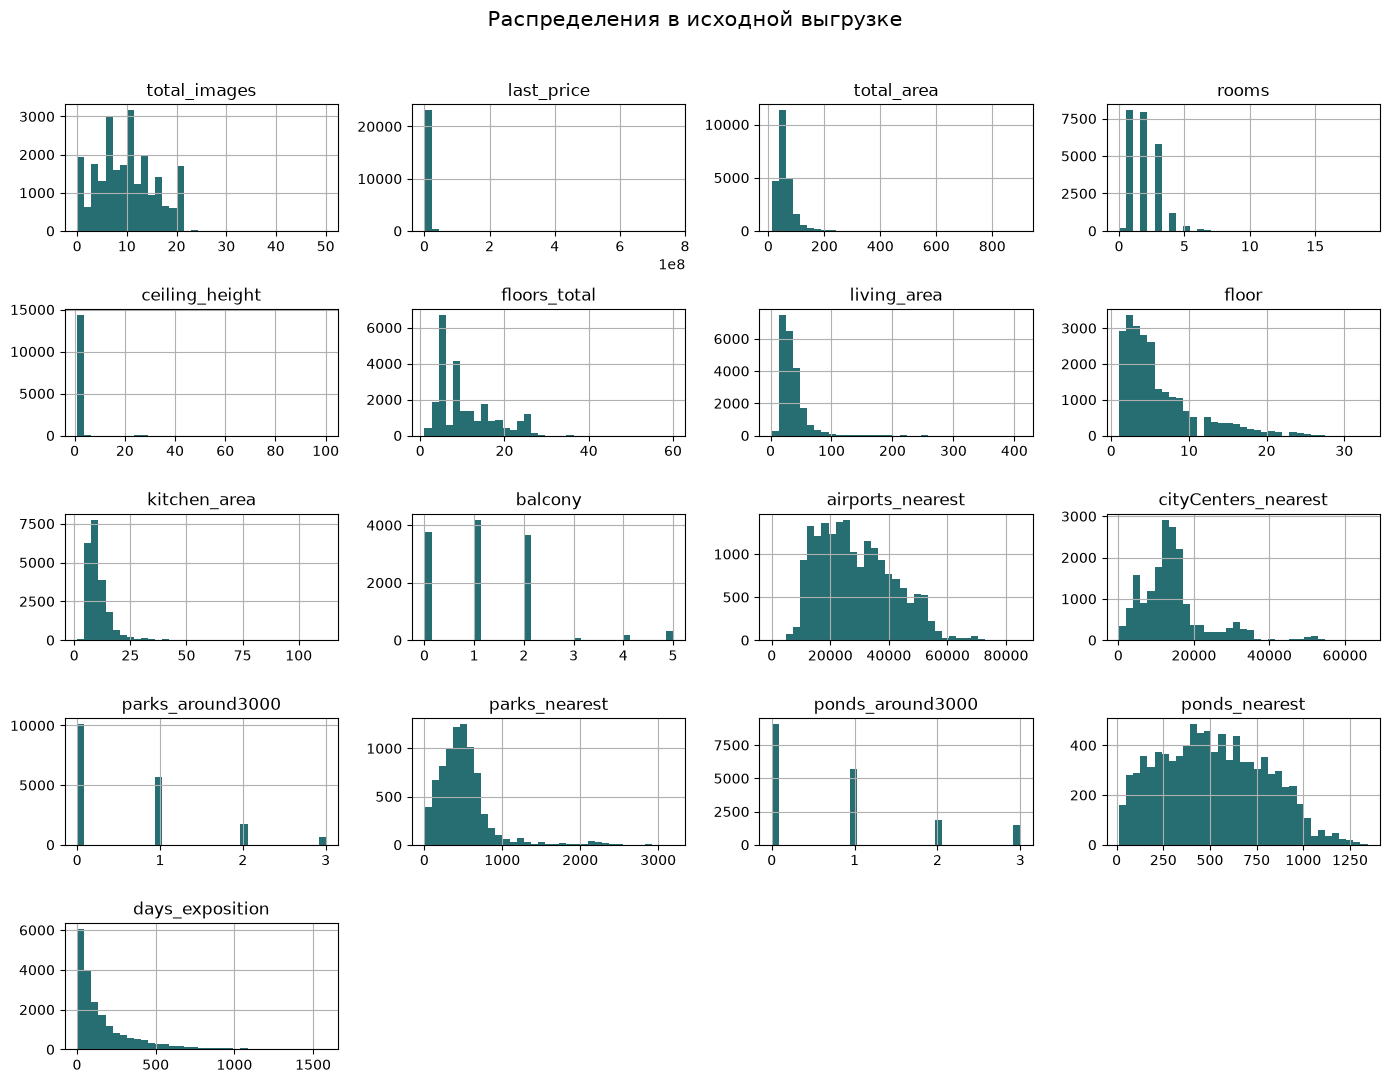

,count,mean,std,min,0.5%,25%,50%,75%,99.5%,max
total_images,23699.0,9.86,5.68,0.0,0.0,6.00,9.00,14.0,20.00,50.0
last_price,23699.0,6541548.77,10887013.27,12190.0,800000.0,3400000.00,4650000.00,6800000.0,54510000.00,763000000.0
total_area,23699.0,60.35,35.65,12.0,23.5,40.00,52.00,69.9,248.85,900.0
rooms,23699.0,2.07,1.08,0.0,0.0,1.00,2.00,3.0,6.00,19.0
ceiling_height,14504.0,2.77,1.26,1.0,2.5,2.52,2.65,2.8,4.10,100.0
floors_total,23613.0,10.67,6.60,1.0,2.0,5.00,9.00,16.0,27.00,60.0
living_area,21796.0,34.46,22.03,2.0,11.2,18.60,30.00,42.3,154.02,409.7
floor,23699.0,5.89,4.89,1.0,1.0,2.00,4.00,8.0,24.00,33.0
kitchen_area,21421.0,10.57,5.91,1.3,5.0,7.00,9.10,12.0,42.36,112.0
balcony,12180.0,1.15,1.07,0.0,0.0,0.00,1.00,2.0,5.00,5.0


In [2]:
numeric = raw.select_dtypes(include='number')
axes = numeric.hist(figsize=(14, 11), bins=35, color='#276e72', layout=(5, 4))
fig = axes.flat[0].figure
fig.suptitle('Распределения в исходной выгрузке', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
display(numeric.describe(percentiles=[.005, .25, .5, .75, .995]).T.round(2))

В исходном архиве 23 699 объявлений и 22 столбца. Диапазоны цен, площадей и высот потолка растянуты редкими значениями. На первом графике они сжимают основную массу наблюдений. Ниже отдельно проверим правдоподобие таких значений и ограничим диапазоны подробных гистограмм.

В данных есть два разных источника признаков. Характеристики квартиры мог оставить пустыми продавец. Расстояния и число объектов рядом зависят от полноты картографических данных.

## 2. Предобработка

In [3]:
data = raw.copy()
missing_count = data.isna().sum()
missing_summary = pd.DataFrame({
    'Пропусков': missing_count,
    'Доля, %': (100 * missing_count / len(data)).round(2),
})
display(missing_summary.loc[missing_summary['Пропусков'].gt(0)]
        .sort_values('Пропусков', ascending=False))

geo_columns = ['cityCenters_nearest', 'parks_around3000', 'ponds_around3000']
display(data[geo_columns].isna().value_counts().rename('Объявлений').to_frame())
explicit_duplicates = data.duplicated().sum()
print(f'Полных дубликатов в исходной таблице: {explicit_duplicates}')
data = data.drop_duplicates().copy()

,Пропусков,"Доля, %"
is_apartment,20924,88.29
parks_nearest,15620,65.91
ponds_nearest,14589,61.56
balcony,11519,48.61
ceiling_height,9195,38.80
airports_nearest,5542,23.38
cityCenters_nearest,5519,23.29
parks_around3000,5518,23.28
ponds_around3000,5518,23.28
days_exposition,3181,13.42


Объявлений
cityCenters_nearest parks_around3000 ponds_around3000            
False               False            False                  18180
True                True             True                    5518
                    False            False                      1

Полных дубликатов в исходной таблице: 0


Число балконов не указано почти в половине объявлений. По условию принимаем такой пропуск за 0. Для остальных полей замена требует дополнительных предположений.

- Сведения о кухне, жилой площади, потолках, числе этажей и статусе апартаментов могли не заполнить. Для студий площадь кухни может быть неприменима как отдельное поле. Эти значения оставляем неизвестными.
- У 5 518 объявлений одновременно отсутствуют расстояние до центра и число парков и водоёмов. Это согласуется с неполным покрытием геосервисов. Заполнять нулями такие поля нельзя, поскольку ноль означает известное отсутствие объектов в заданном радиусе.
- Известные расстояния до парка и число парков измеряют разное. Например, четыре расстояния при нулевом числе парков превышают 3 км. Такие записи согласуются с поиском ближайшего парка за пределами радиуса.
- Для части объявлений нет срока размещения. Возможно, они ещё не были сняты к моменту выгрузки или дата снятия не попала в источник. Срок считаем по записям с известными значениями. Объявления без населённого пункта остаются в общих расчётах.

In [4]:
data['balcony'] = data['balcony'].fillna(0)
data['first_day_exposition'] = pd.to_datetime(
    data['first_day_exposition'], format='%Y-%m-%dT%H:%M:%S', errors='raise',
)
data['is_apartment'] = data['is_apartment'].astype('boolean')
data['locality_name'] = data['locality_name'].astype('string').str.strip()

integer_columns = [
    'last_price', 'floors_total', 'balcony', 'parks_around3000',
    'ponds_around3000', 'days_exposition',
]
for column in integer_columns:
    values = data[column].dropna()
    if not np.isclose(values, values.round(), rtol=0).all():
        raise ValueError(f'В столбце {column} есть дробные значения.')
    data[column] = data[column].round().astype('Int64')

display(data.dtypes.rename('Тип после преобразования').to_frame())

,Тип после преобразования
total_images,int64
last_price,Int64
total_area,float64
first_day_exposition,datetime64[us]
rooms,int64
ceiling_height,float64
floors_total,Int64
living_area,float64
floor,int64
is_apartment,boolean


Дату преобразовали в datetime для выделения дня недели, месяца и года. Число балконов, этажность, число парков и водоёмов и длительность публикации целочисленные по смыслу. Цена в файле также задана в целых рублях. Значения длительности вроде 45,00000000000001 отличаются от целых только погрешностью хранения. Используем целочисленный тип Int64 с поддержкой пропусков, а признак апартаментов храним в булевом типе с поддержкой пропусков.

In [5]:
names_before = data['locality_name'].nunique()
data['locality_clean'] = (
    data['locality_name']
    .str.replace('ё', 'е', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.replace(r'^(?:городской поселок|поселок городского типа) ', 'поселок ', regex=True)
    .str.replace(r'^поселок при железнодорожной станции ', 'поселок станции ', regex=True)
    .replace({'поселок Мурино': 'Мурино', 'деревня Кудрово': 'Кудрово'})
)
alias_table = data[['locality_name', 'locality_clean']].dropna().drop_duplicates()
changed_groups = (
    alias_table.groupby('locality_clean')['locality_name']
    .agg(lambda names: ', '.join(sorted(names)))
)
alias_count = alias_table.groupby('locality_clean').size()
display(changed_groups.loc[alias_count.gt(1)].rename('Исходные варианты').to_frame())
print(f'Уникальных названий: {names_before} до нормализации, '
      f'{data["locality_clean"].nunique()} после.')
normalized_duplicates = data.drop(columns='locality_name').duplicated().sum()
print(f'Повторов строк после сравнения по нормализованному названию: {normalized_duplicates}')
data = data.loc[~data.drop(columns='locality_name').duplicated()].copy()

,Исходные варианты
locality_clean,
Кудрово,"Кудрово, деревня Кудрово"
Мурино,"Мурино, поселок Мурино, посёлок Мурино"
поселок Аннино,"поселок Аннино, посёлок Аннино"
поселок Большая Ижора,"городской поселок Большая Ижора, поселок город..."
поселок Бугры,"поселок Бугры, посёлок Бугры"
поселок Возрождение,"поселок Возрождение, посёлок Возрождение"
поселок Вырица,"поселок городского типа Вырица, посёлок городс..."
поселок Гаврилово,"поселок Гаврилово, посёлок Гаврилово"
поселок Жилгородок,"поселок Жилгородок, посёлок Жилгородок"


Уникальных названий: 364 до нормализации, 318 после.
Повторов строк после сравнения по нормализованному названию: 0


Нормализовали «ё» и «е» и варианты наименования посёлков. Отдельно свели старые названия Мурино и Кудрово с названиями городов. Для неоднозначных совпадений сохранили тип населённого пункта. Например, деревню и посёлок Фёдоровское по одному общему слову не объединяем.

[Петростат, изменения в административно-территориальном устройстве Ленинградской области](https://78.rosstat.gov.ru/storage/mediabank/14000224_%D0%9E%D1%81%D0%BD%D0%BE%D0%B2%D0%BD%D0%BE%D0%B9_%D0%9B%D0%9E%202023.pdf)

In [6]:
# Исправляем вероятное смещение десятичного разделителя только для узкого диапазона.
decimal_shift = data['ceiling_height'].between(20, 40)
data.loc[decimal_shift, 'ceiling_height'] /= 10
unusual_height = data['ceiling_height'].notna() & ~data['ceiling_height'].between(2, 6)
data.loc[unusual_height, 'ceiling_height'] = np.nan

# Общая площадь пригодна для анализа, но разбивка по помещениям противоречива.
inconsistent_area = (data['living_area'] + data['kitchen_area']).gt(data['total_area'] + .01)
data.loc[inconsistent_area, ['living_area', 'kitchen_area']] = np.nan

# Четыре площади 2–3 м² отделены от остальных значений и сомнительны.
small_living_area = data['living_area'].lt(5)
display(data.loc[small_living_area, ['total_area', 'living_area', 'kitchen_area', 'rooms', 'studio']])
data.loc[small_living_area, 'living_area'] = np.nan

# Выявляем строки с неправдоподобной ценой или невозможным этажом.
invalid_price_or_area = (
    data['total_area'].le(0) | data['last_price'].le(0)
    | (data['last_price'] / data['total_area']).lt(1_000)
)
invalid_floor = (
    data['floor'].lt(1) | data['floor'].gt(data['floors_total']).fillna(False)
)
excluded = invalid_price_or_area | invalid_floor
display(data.loc[excluded, ['last_price', 'total_area', 'floor', 'floors_total', 'locality_clean']])
data = data.loc[~excluded].copy()

display(pd.Series({
    'Высоты, разделённые на 10': decimal_shift.sum(),
    'Необъяснимые высоты, заменённые пропусками': unusual_height.sum(),
    'Записи с несогласованными жилой площадью и кухней': inconsistent_area.sum(),
    'Сомнительные жилые площади ниже 5 м²': small_living_area.sum(),
    'Исключено записей с некорректной ценой или этажом': excluded.sum(),
    'Записей для анализа': len(data),
}, name='Количество').to_frame())

,total_area,living_area,kitchen_area,rooms,studio
3242,41.0,3.0,11.0,1,False
13915,52.0,2.0,9.0,2,False
21758,23.0,2.0,NaN,0,True
23574,139.0,3.0,16.0,3,False


,last_price,total_area,floor,floors_total,locality_clean
8793,12190,109.0,25,25,Санкт-Петербург


,Количество
"Высоты, разделённые на 10",22
"Необъяснимые высоты, заменённые пропусками",10
Записи с несогласованными жилой площадью и кухней,64
Сомнительные жилые площади ниже 5 м²,4
Исключено записей с некорректной ценой или этажом,1
Записей для анализа,23698


Значения потолка от 20 до 40 м делим на 10. Они превращаются в правдоподобные 2–4 м, повторяются у квартир обычных размеров и этажности и согласуются с примерами из задания. Другие высоты за границами 2–6 м исключаем из анализа высоты. По ним нельзя надёжно восстановить исходное значение. Для 64 квартир, где сумма жилой площади и площади кухни превышает общую, оставляем общую площадь и считаем обе составляющие неизвестными. Четыре жилые площади 2–3 м² также считаем неизвестными: эти значения отделены от следующего наблюдения в 5 м² и встречаются при общей площади 23–139 м². Объявления сохраняем. Порог относится к этой выгрузке и служит проверке качества данных.

В Санкт-Петербурге обнаружена квартира 109 м² за 12 190 ₽, около 112 ₽/м². Исключаем её по диагностической границе 1 000 ₽/м². Это единственная запись ниже порога. Нулевое число комнат сохраняем: все такие записи отмечены как студии или свободная планировка. Кухня 1,3 м² и здание с 60 этажами требуют сверки с источником. В строках нет противоречий площади или номера этажа, поэтому сохраняем их для расчётов и отдельно показываем основной диапазон на гистограммах.

## 3. Новые признаки

In [7]:
data['price_per_m2'] = (data['last_price'].astype(float) / data['total_area'].astype(float)).round(2)
publication = data['first_day_exposition'].dt
data['publication_weekday'] = publication.day_of_week
data['publication_month'] = publication.month
data['publication_year'] = publication.year

floor_type = pd.Series(pd.NA, index=data.index, dtype='string')
first_floor = data['floor'].eq(1)
known_floors = data['floors_total'].notna()
floor_type.loc[known_floors] = 'другой'
floor_type.loc[data['floor'].eq(data['floors_total']).fillna(False)] = 'последний'
floor_type.loc[first_floor] = 'первый'
data['floor_type'] = floor_type
data['center_km'] = np.floor(data['cityCenters_nearest'] / 1_000 + .5).astype('Int64')

feature_columns = [
    'price_per_m2', 'publication_weekday', 'publication_month',
    'publication_year', 'floor_type', 'center_km',
]
if not data['price_per_m2'].ge(1_000).all() or data['publication_weekday'].isna().any():
    raise ValueError('Проверьте расчёт цены квадратного метра и даты публикации.')
if not data['price_per_m2'].equals((data['last_price'].astype(float) / data['total_area'].astype(float)).round(2)):
    raise ValueError('Цена квадратного метра рассчитана неверно.')

display(data[feature_columns].head())
display(data[feature_columns].isna().sum().rename('Пропусков').to_frame())

,price_per_m2,publication_weekday,publication_month,publication_year,floor_type,center_km
0,120370.37,3,3,2019,другой,16
1,82920.79,1,12,2018,первый,19
2,92785.71,3,8,2015,другой,14
3,408176.10,4,7,2015,другой,7
4,100000.00,1,6,2018,другой,8


,Пропусков
price_per_m2,0
publication_weekday,0
publication_month,0
publication_year,0
floor_type,83
center_km,5519


В одноэтажном доме приоритет у категории «первый». Если квартира выше первого этажа и этажность дома неизвестна, тип остаётся пропуском. Расстояния округлены до ближайшего целого километра, ровно 500 м округляются вверх. В группу «0 км» попадают расстояния меньше 500 м.

## 4. Исследовательский анализ

### 4.1. Распределения характеристик квартир

Для подробных числовых графиков опускаем значения ниже 0,5-го и выше 99,5-го процентилей по каждому признаку отдельно. Это сохраняет основную часть данных и позволяет видеть форму распределения. Для числа комнат сохраняем реальные студии с нулём комнат. Показываем число значений, использованное в каждом графике. Медианы и квартили ниже посчитаны по всем очищенным значениям.

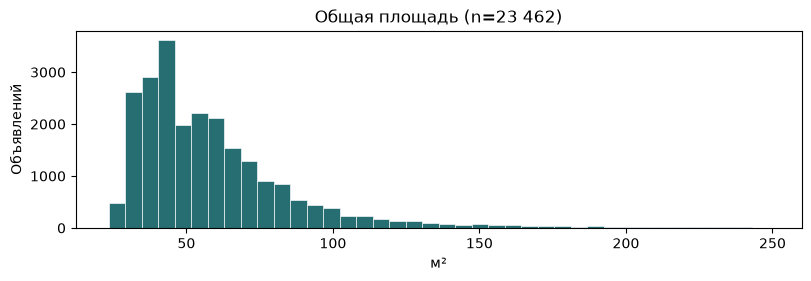

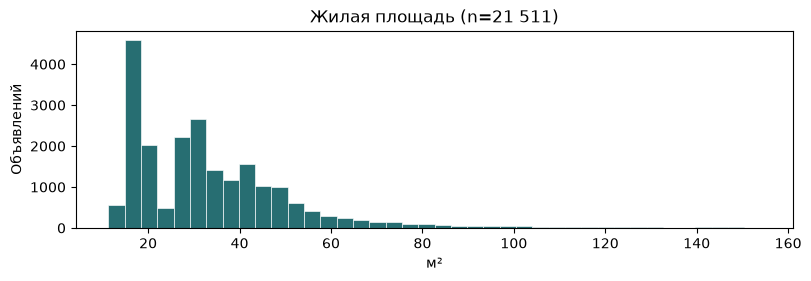

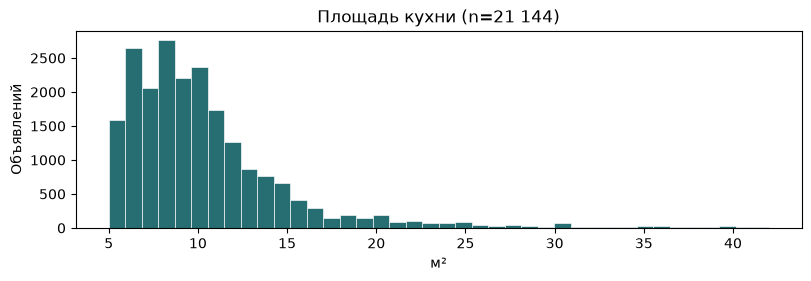

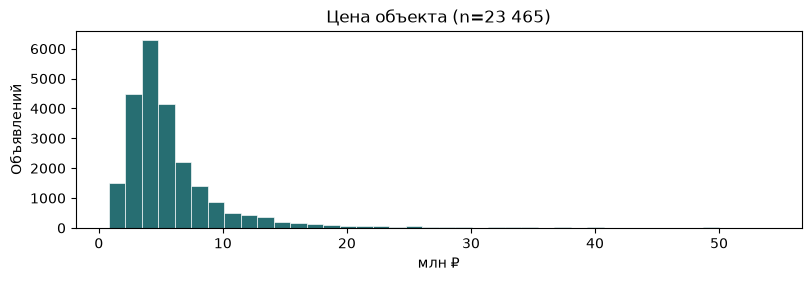

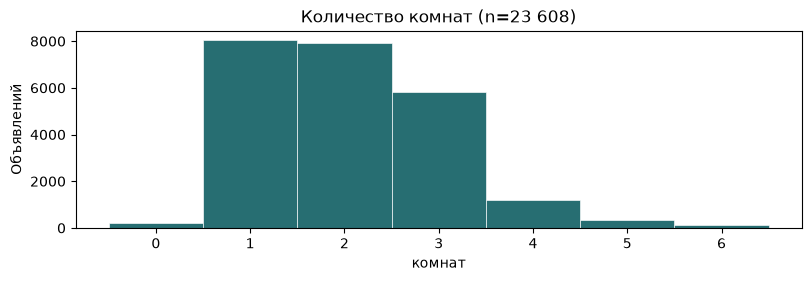

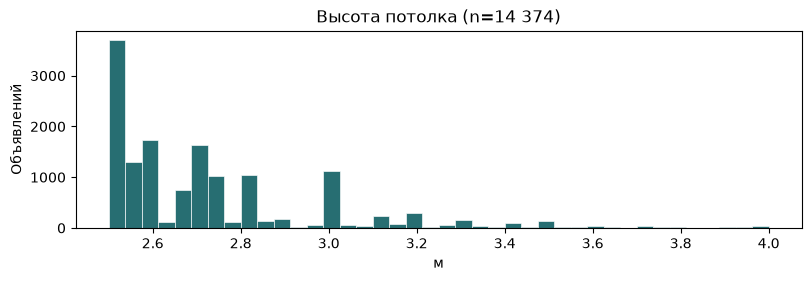

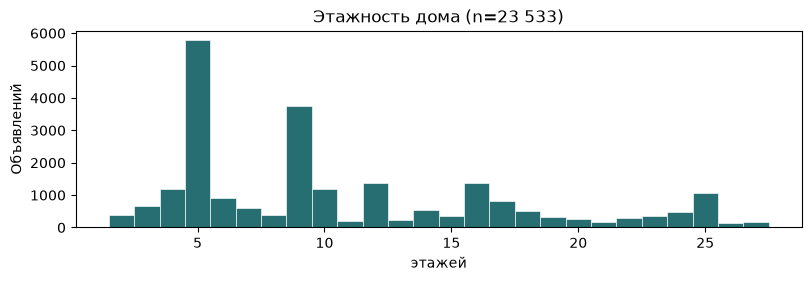

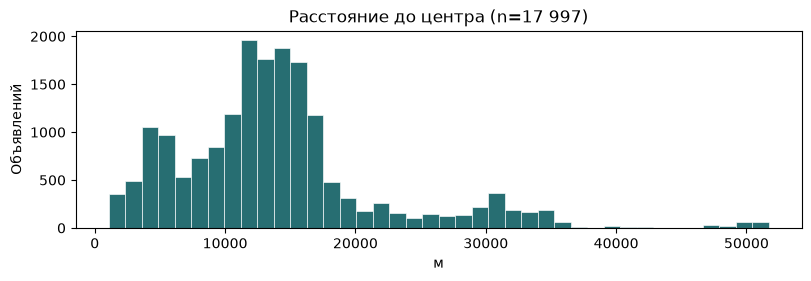

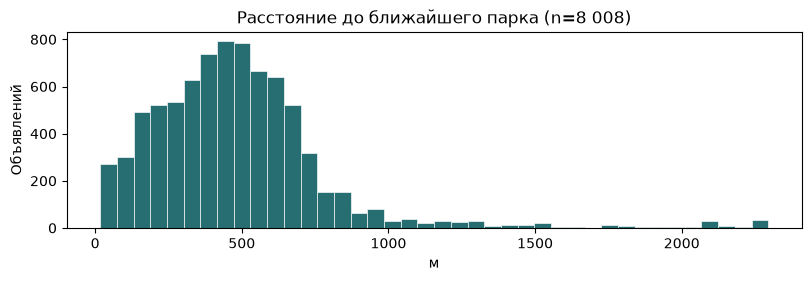

,Известных,На графике,25%,Медиана,75%
Параметр,,,,,
"Общая площадь, м²",23698,23462,40.00,52.00,69.88
"Жилая площадь, м²",21727,21511,18.60,30.00,42.30
"Площадь кухни, м²",21356,21144,7.00,9.10,12.00
"Цена объекта, млн ₽",23698,23465,3.40,4.65,6.80
"Количество комнат, комнат",23698,23608,1.00,2.00,3.00
"Высота потолка, м",14493,14374,2.51,2.65,2.80
"Этажность дома, этажей",23612,23533,5.00,9.00,16.00
"Расстояние до центра, м",18179,17997,9238.00,13099.00,16293.00
"Расстояние до ближайшего парка, м",8078,8008,288.00,455.00,612.00


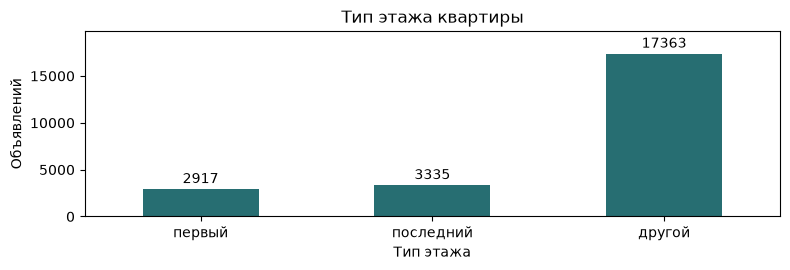

In [8]:
features = {
    'total_area': ('Общая площадь', 'м²'),
    'living_area': ('Жилая площадь', 'м²'),
    'kitchen_area': ('Площадь кухни', 'м²'),
    'last_price': ('Цена объекта', 'млн ₽'),
    'rooms': ('Количество комнат', 'комнат'),
    'ceiling_height': ('Высота потолка', 'м'),
    'floors_total': ('Этажность дома', 'этажей'),
    'cityCenters_nearest': ('Расстояние до центра', 'м'),
    'parks_nearest': ('Расстояние до ближайшего парка', 'м'),
}

def central_values(values, lower=.005, upper=.995):
    values = values.dropna()
    left, right = values.quantile([lower, upper])
    return values.loc[values.between(left, right)]

distribution_rows = []
for column, (title, unit) in features.items():
    values = data[column].dropna()
    if column == 'rooms':
        main = values.loc[values.le(values.quantile(.995))]
    else:
        main = central_values(values)
    scale = 1_000_000 if column == 'last_price' else 1
    bins = (np.arange(main.min(), main.max() + 2) - .5
            if column in ['rooms', 'floors_total'] else 40)
    fig, ax = plt.subplots(figsize=(8, 2.7), constrained_layout=True)
    ax.hist(main.astype(float) / scale, bins=bins, color='#276e72', edgecolor='white',
            linewidth=.45)
    ax.set(title=f'{title} (n={len(main):,})'.replace(',', ' '),
           xlabel=unit, ylabel='Объявлений')
    plt.show()
    distribution_rows.append({
        'Параметр': f'{title}, {unit}', 'Известных': len(values), 'На графике': len(main),
        '25%': values.quantile(.25) / scale, 'Медиана': values.median() / scale,
        '75%': values.quantile(.75) / scale,
    })
distributions = pd.DataFrame(distribution_rows).set_index('Параметр')
display(distributions.round(2))

floor_order = ['первый', 'последний', 'другой']
floor_counts = data['floor_type'].value_counts().reindex(floor_order)
ax = floor_counts.astype(int).plot.bar(figsize=(8, 2.8), rot=0, color='#276e72')
ax.set(title='Тип этажа квартиры', xlabel='Тип этажа', ylabel='Объявлений')
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(str(int(height)), (bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 2), textcoords='offset points', ha='center', va='bottom')
ax.margins(y=.14)
plt.tight_layout()
plt.show()

**Площадь и цена.** Медианная общая площадь составляет 52 м². Медианы жилой площади и площади кухни равны 30 и 9,1 м². У всех трёх распределений есть правый хвост. Половина цен лежит между 3,40 и 6,80 млн ₽ при медиане 4,65 млн ₽.

**Планировка и дом.** Однокомнатных и двухкомнатных квартир примерно поровну. Вместе они составляют около 67% выборки. Трёхкомнатные встречаются реже, квартир с четырьмя и более комнатами ещё меньше. Самые заметные пики по этажности приходятся на 5 и 9 этажей. На промежуточных этажах находятся 17 363 квартиры из 23 615 с известным типом этажа. Медианная высота потолка составляет 2,65 м. Половина известных высот лежит между 2,51 и 2,80 м.

**Расположение.** Медианное расстояние до центра составляет около 13,1 км, до ближайшего парка 455 м. Для половины квартир с известным расстоянием до парка оно составляет от 288 до 612 м. Эти выводы относятся к объявлениям с картографическими данными.

### 4.2. Срок размещения объявления

,Значение
Срок указан,20517.00
Срок не указан,3181.00
"Среднее, дней",180.90
"Медиана, дней",95.00
"Первый квартиль, дней",45.00
"Третий квартиль, дней",232.00
"Граница долгого размещения, дней",512.50
"Быстрые (до первого квартиля включительно), %",29.11
"Долгие (выше границы), %",8.13


,Объявлений
days_exposition,
45,880
60,538
7,234
30,208
90,204


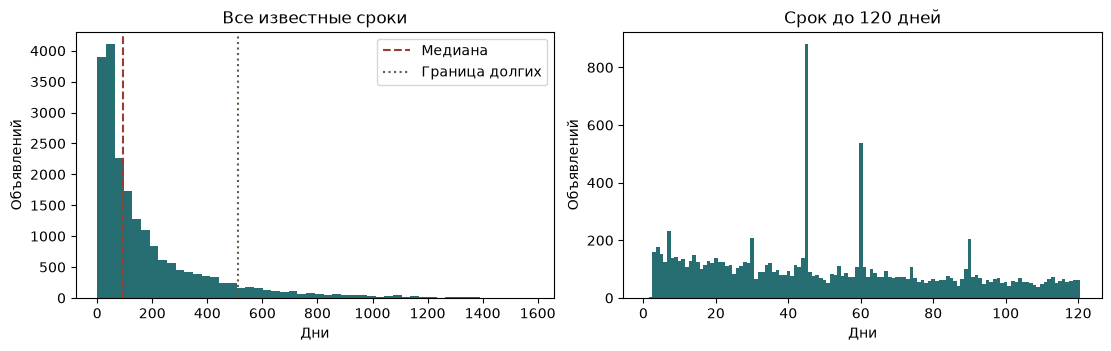

Без двух самых частых сроков: среднее 190.6, медиана 108 дней.


In [9]:
exposure = data['days_exposition'].dropna().astype(int)
q1, median_days, q3 = exposure.quantile([.25, .5, .75])
upper_fence = q3 + 1.5 * (q3 - q1)
exposure_summary = pd.Series({
    'Срок указан': len(exposure), 'Срок не указан': data['days_exposition'].isna().sum(),
    'Среднее, дней': exposure.mean(), 'Медиана, дней': median_days,
    'Первый квартиль, дней': q1, 'Третий квартиль, дней': q3,
    'Граница долгого размещения, дней': upper_fence,
    'Быстрые (до первого квартиля включительно), %': 100 * exposure.le(q1).mean(),
    'Долгие (выше границы), %': 100 * exposure.gt(upper_fence).mean(),
})
display(exposure_summary.round(2).rename('Значение').to_frame())
display(exposure.value_counts().head(5).rename('Объявлений').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
axes[0].hist(exposure, bins=50, color='#276e72')
axes[0].axvline(median_days, color='#953f31', linestyle='--', label='Медиана')
axes[0].axvline(upper_fence, color='#665a4c', linestyle=':', label='Граница долгих')
axes[0].set(title='Все известные сроки', xlabel='Дни', ylabel='Объявлений')
axes[0].legend()
early_days = exposure.loc[exposure.le(120)]
axes[1].hist(early_days, bins=np.arange(.5, 121.5, 1), color='#276e72')
axes[1].set(title='Срок до 120 дней', xlabel='Дни', ylabel='Объявлений')
plt.show()

without_spikes = exposure.loc[~exposure.isin([45, 60])]
print(f'Без двух самых частых сроков: среднее {without_spikes.mean():.1f}, '
      f'медиана {without_spikes.median():.0f} дней.')

По 20 517 объявлениям с известным сроком медиана размещения составляет 95 дней, среднее около 181 дня. Среднее выше из-за объявлений, которые долго оставались на сайте. Для этого анализа быстрым считаю срок до 45 дней включительно, долгим срок от 513 дней. Первая граница соответствует нижнему квартилю, вторая лежит выше верхней границы диаграммы размаха (512,5 дня). При таком расчёте быстрых размещений 29,11%, долгих 8,13%. Доля быстрых больше четверти из-за большого числа объявлений на границе 45 дней.

На 45-й день сняли 880 объявлений, на 60-й день сняли 538. Пики могут быть связаны с правилами размещения. По данным выгрузки причину снятия установить нельзя. Если в качестве проверки исключить эти два дня, медиана составит 108 дней, среднее 191 день. В обоих расчётах медианный срок остаётся в пределах трёх или четырёх месяцев.

### 4.3. Связь полной цены с характеристиками и датой публикации

Для количественных признаков покажем диаграммы плотности точек и коэффициенты Пирсона и Спирмена. Пирсон измеряет линейную связь и чувствителен к дорогим и крупным объектам, Спирмен показывает, насколько согласован порядок значений. Сравним коэффициенты на всех известных парах и на основном диапазоне, показанном на рисунках. Для категорий и дат сравним медианные цены и числа объявлений.

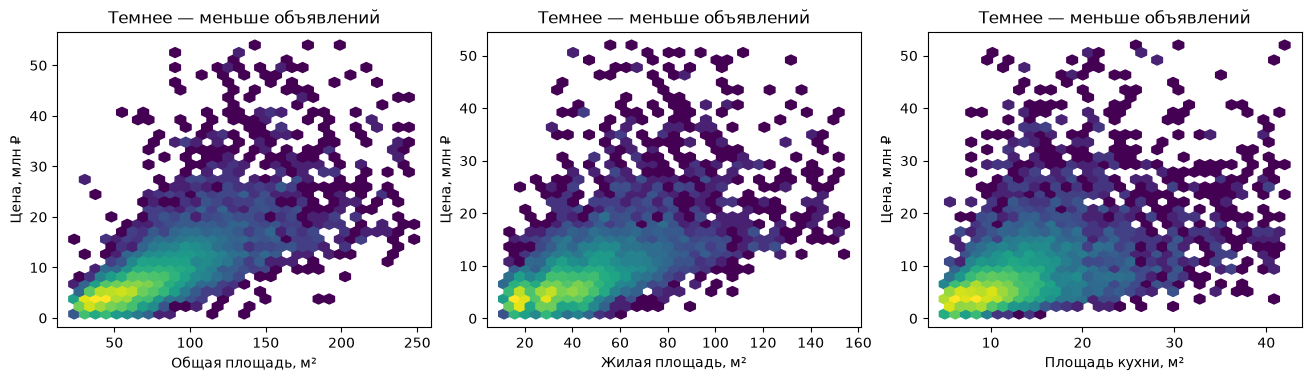

,Пар,"Пирсон, все","Спирмен, все",Пар на графике,"Пирсон, основной диапазон","Спирмен, основной диапазон"
Признак,,,,,,
"Общая площадь, м²",23698,0.654,0.749,23283,0.771,0.740
"Жилая площадь, м²",21727,0.568,0.641,21345,0.667,0.635
"Площадь кухни, м²",21356,0.522,0.582,20965,0.587,0.568


In [10]:
areas = {
    'total_area': 'Общая площадь, м²',
    'living_area': 'Жилая площадь, м²',
    'kitchen_area': 'Площадь кухни, м²',
}
correlation_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)
for ax, (column, x_label) in zip(axes, areas.items()):
    pairs = data[[column, 'last_price']].dropna().astype(float)
    main_x = central_values(pairs[column])
    main_y = central_values(pairs['last_price'])
    main = pairs.loc[pairs.index.isin(main_x.index) & pairs.index.isin(main_y.index)]
    ax.hexbin(main[column], main['last_price'] / 1_000_000,
              gridsize=32, bins='log', mincnt=1, cmap='viridis')
    ax.set(xlabel=x_label, ylabel='Цена, млн ₽', title='Темнее — меньше объявлений')
    correlation_rows.append({
        'Признак': x_label, 'Пар': len(pairs),
        'Пирсон, все': pairs[column].corr(pairs['last_price']),
        'Спирмен, все': pairs[column].corr(pairs['last_price'], method='spearman'),
        'Пар на графике': len(main),
        'Пирсон, основной диапазон': main[column].corr(main['last_price']),
        'Спирмен, основной диапазон': main[column].corr(main['last_price'], method='spearman'),
    })
plt.show()
area_correlation = pd.DataFrame(correlation_rows).set_index('Признак')
display(area_correlation.round(3))

,Объявлений,"Медиана, ₽"
rooms,,
0,197,2700000.0
1,8047,3600000.0
2,7939,4770338.0
3,5814,6200000.0
4,1180,9000000.0
5,326,14000000.0
6,105,19000000.0
7,59,24900000.0
8,12,23095000.0


,Объявлений,"Медиана, ₽"
floor_type,,
первый,2917,3900000.0
последний,3335,4300000.0
другой,17363,4850000.0


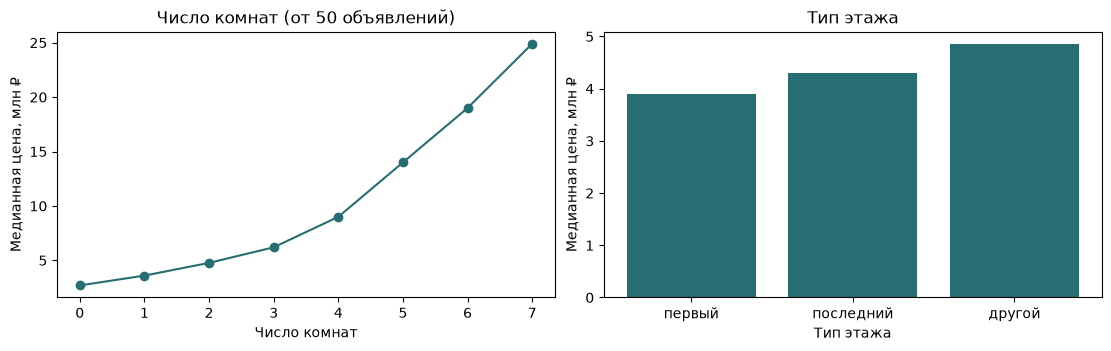

In [11]:
def price_summary(group):
    return data.pivot_table(index=group, values='last_price', aggfunc=['count', 'median'],
                            observed=True).droplevel(1, axis=1).rename(
                                columns={'count': 'Объявлений', 'median': 'Медиана, ₽'}
                            )

room_price = price_summary('rooms')
floor_price = price_summary('floor_type').reindex(floor_order)
display(room_price)
display(floor_price)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
main_rooms = room_price.loc[room_price['Объявлений'].ge(50)]
axes[0].plot(main_rooms.index.to_numpy(),
             main_rooms['Медиана, ₽'].to_numpy(dtype=float) / 1_000_000,
             'o-', color='#276e72')
axes[0].set(title='Число комнат (от 50 объявлений)', xlabel='Число комнат',
            xticks=main_rooms.index)
axes[1].bar(floor_price.index, floor_price['Медиана, ₽'].to_numpy(dtype=float) / 1_000_000,
            color='#276e72')
axes[1].set(title='Тип этажа', xlabel='Тип этажа')
for ax in axes:
    ax.set_ylabel('Медианная цена, млн ₽')
plt.show()

,Объявлений,"Медиана, ₽"
День недели,,
0,3612,4650000.0
1,4183,4730000.0
2,3973,4700000.0
3,4295,4650000.0
4,4000,4585000.0
5,1936,4555000.0
6,1699,4550000.0


,Объявлений,"Медиана, ₽"
Месяц,,
1,1500,4600000.0
2,2640,4650000.0
3,2586,4650000.0
4,2379,4800000.0
5,1274,4515000.0
6,1760,4400000.0
7,1695,4650000.0
8,1744,4570000.0
9,1981,4700000.0


,Объявлений,"Медиана, ₽"
Год,,
2014,137,7700000.0
2015,1191,5350000.0
2016,2783,4550000.0
2017,8190,4500000.0
2018,8519,4550000.0
2019,2878,5050000.0


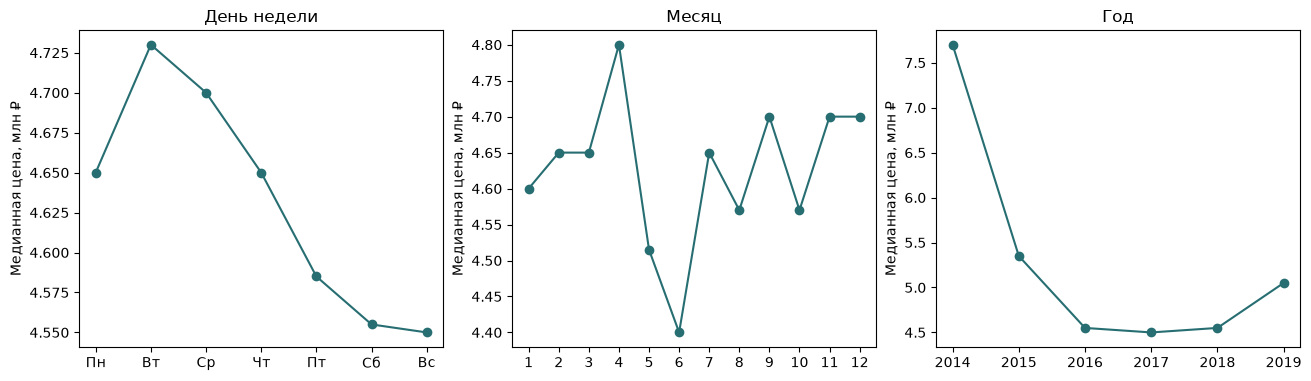

,min,max
publication_year,,
2014,2014-11-27,2014-12-29
2015,2015-01-02,2015-12-31
2016,2016-01-04,2016-12-30
2017,2017-01-01,2017-12-31
2018,2018-01-01,2018-12-31
2019,2019-01-01,2019-05-03


In [12]:
calendar_fields = {
    'publication_weekday': 'День недели',
    'publication_month': 'Месяц',
    'publication_year': 'Год',
}
weekdays = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
calendar_summary = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)
for ax, (column, title) in zip(axes, calendar_fields.items()):
    table = price_summary(column)
    calendar_summary[column] = table
    display(table.rename_axis(title))
    ax.plot(table.index.to_numpy(), table['Медиана, ₽'].to_numpy(dtype=float) / 1_000_000,
            'o-', color='#276e72')
    ax.set(title=title, ylabel='Медианная цена, млн ₽', xticks=table.index)
    if column == 'publication_weekday':
        ax.set_xticklabels(weekdays)
plt.show()
display(data.groupby('publication_year')['first_day_exposition'].agg(['min', 'max']))

**Площадь и комнаты.** Среди размеров самая сильная связь полной цены с общей площадью (Пирсон 0,65, Спирмен 0,75), затем идут жилая площадь (0,57 и 0,64) и кухня (0,52 и 0,58). После ограничения диапазонов порядок сохраняется. Медианная цена растёт с количеством комнат в достаточно крупных группах: 3,60 млн ₽ при одной комнате, 4,77 млн ₽ при двух и 6,20 млн ₽ при трёх. Число комнат связано с общей площадью, поэтому по этим сравнениям вклад каждого признака в отдельности выделить нельзя.

**Этаж.** Медиана цены составляет 3,90 млн ₽ на первом этаже, 4,30 млн ₽ на последнем и 4,85 млн ₽ на промежуточных. Разница между первым и промежуточными этажами составляет 0,95 млн ₽. Для оценки поправки к цене нужно сравнить схожие объявления по площади, району и типу дома.

**Календарь.** Медианы по дням недели лежат в диапазоне 4,55–4,73 млн ₽, по месяцам от 4,40 до 4,80 млн ₽. В полных 2016–2018 годах медианы близки: 4,50–4,55 млн ₽. Высокое значение 2014 года (7,70 млн ₽) основано на 137 объявлениях конца года, а данные за 2019 год заканчиваются 3 мая. Эти ряды не позволяют отделить календарный эффект от изменения состава объявлений.

### 4.4. Средняя цена квадратного метра в десяти населённых пунктах

,Объявлений,"Средняя цена м², ₽","Медиана цены м², ₽"
locality_clean,,,
Санкт-Петербург,15720,114856.31,104766.08
Мурино,590,86087.51,86175.64
Кудрово,472,95324.93,95675.48
поселок Шушары,440,78677.36,76876.18
Всеволожск,398,68654.47,65789.47
Пушкин,369,103125.82,100000.00
Колпино,338,75424.58,74723.74
поселок Парголово,327,90175.91,91642.86
Гатчина,307,68746.15,67796.61


Самая высокая средняя в десятке: Санкт-Петербург
Самая низкая средняя в десятке: Выборг


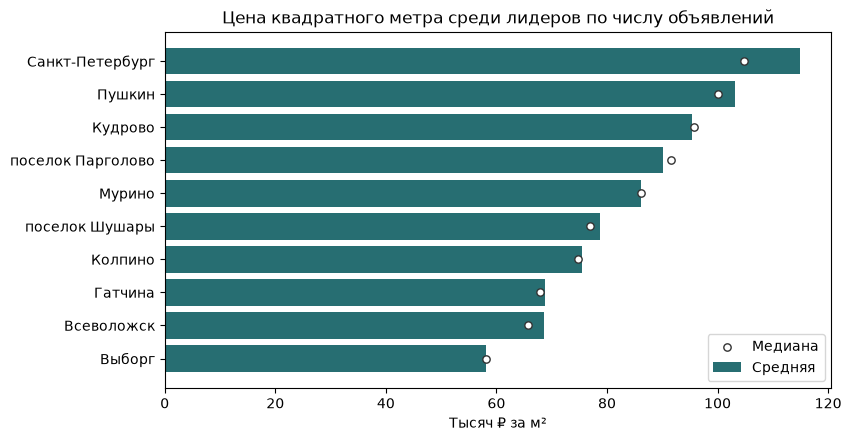

In [13]:
locality_price = data.pivot_table(
    index='locality_clean', values='price_per_m2',
    aggfunc=['count', 'mean', 'median'], observed=True,
).droplevel(1, axis=1)
top_localities = locality_price.sort_values('count', ascending=False).head(10)
display(top_localities.rename(columns={
    'count': 'Объявлений', 'mean': 'Средняя цена м², ₽', 'median': 'Медиана цены м², ₽',
}).round(2))
most_expensive = top_localities['mean'].idxmax()
least_expensive = top_localities['mean'].idxmin()
print(f'Самая высокая средняя в десятке: {most_expensive}')
print(f'Самая низкая средняя в десятке: {least_expensive}')

localities_plot = top_localities.sort_values('mean')
fig, ax = plt.subplots(figsize=(8.4, 4.3), constrained_layout=True)
ax.barh(localities_plot.index, localities_plot['mean'].astype(float) / 1_000,
        color='#276e72', label='Средняя')
ax.scatter(localities_plot['median'].astype(float) / 1_000, localities_plot.index,
           facecolors='white', edgecolors='#333333', s=28, zorder=3, label='Медиана')
ax.set(title='Цена квадратного метра среди лидеров по числу объявлений',
       xlabel='Тысяч ₽ за м²')
ax.legend(loc='lower right')
plt.show()

**Вывод.** Из десяти населённых пунктов с наибольшим числом объявлений дороже всего квадратный метр в Санкт-Петербурге (114 856 ₽ в среднем), дешевле всего в Выборге (58 142 ₽). Разница около 56,7 тыс. ₽/м², почти вдвое. Медианы сохраняют тот же порядок для этих двух городов. Только Санкт-Петербург дал 15 720 объявлений, поэтому при построении общих ценовых ориентиров важно учитывать географию выборки.

### 4.5. Цена квартир в Петербурге по расстоянию до центра

,Объявлений,"Средняя цена, ₽","Медианная цена, ₽"
center_km,,,
0,27,31449116.0,17900000.0
1,192,21206721.0,11395000.0
2,310,17788320.0,10000000.0
3,350,11126581.0,8409000.0
4,686,13311362.0,9200000.0
5,922,14491260.0,9500000.0
6,618,15338418.0,8900000.0
7,420,14775153.0,7800000.0
8,597,9957717.0,7450000.0


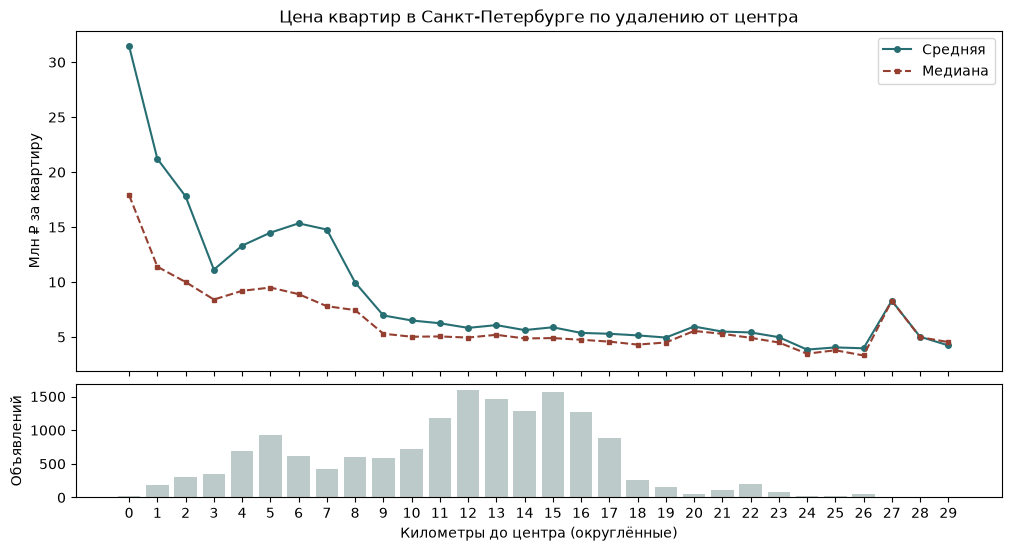

С известным расстоянием до центра: 15 659 из 15 720 объявлений.


In [14]:
spb = data.loc[data['locality_clean'].eq('Санкт-Петербург')]
km_price = spb.assign(last_price=spb['last_price'].astype(float)).pivot_table(
    index='center_km', values='last_price', aggfunc=['count', 'mean', 'median'],
    observed=True,
).droplevel(1, axis=1)
display(km_price.rename(columns={
    'count': 'Объявлений', 'mean': 'Средняя цена, ₽', 'median': 'Медианная цена, ₽',
}).round(0))

fig, (ax, ax_count) = plt.subplots(
    2, 1, figsize=(10, 5.4), sharex=True, gridspec_kw={'height_ratios': [3, 1]}, constrained_layout=True,
)
kilometers = km_price.index.to_numpy(dtype=int)
ax.plot(kilometers, km_price['mean'].to_numpy() / 1_000_000, 'o-', color='#276e72',
        markersize=4, label='Средняя')
ax.plot(kilometers, km_price['median'].to_numpy() / 1_000_000, 's--', color='#953f31',
        markersize=3, label='Медиана')
ax.set(title='Цена квартир в Санкт-Петербурге по удалению от центра',
       ylabel='Млн ₽ за квартиру')
ax.legend()
ax_count.bar(kilometers, km_price['count'].to_numpy(), color='#bccac9')
ax_count.set(xlabel='Километры до центра (округлённые)', ylabel='Объявлений',
             xticks=kilometers)
plt.show()

if km_price['count'].sum() != spb['center_km'].notna().sum():
    raise ValueError('Группировка по километрам охватила не все известные расстояния.')
print(f'С известным расстоянием до центра: {spb["center_km"].notna().sum():,} '
      f'из {len(spb):,} объявлений.'.replace(',', ' '))

**Вывод.** В целом по мере удаления от центра цена снижается. Средняя полная цена составляет 21,21 млн ₽ в интервале около 1 км, 6,51 млн ₽ около 10 км и 5,88 млн ₽ около 15 км. Медианы соответственно 11,40, 5,03 и 4,90 млн ₽. Разрыв между средней и медианой особенно велик рядом с центром, где заметно влияние дорогих объявлений.

Снижение идёт не на каждом километре. В диапазоне 4–7 км средняя поднимается относительно 3 км. На 27-м километре среднее 8,30 млн ₽ основано всего на двух объявлениях. Число наблюдений и медиана на графике помогают не принять такие колебания за устойчивую закономерность. Для сравнения одинаковых объектов по расстоянию нужно учитывать площадь, район и характеристики дома.

## 5. Общий вывод

В анализ вошли 23 698 объявлений. Я исключил одну запись с неправдоподобной ценой, привёл названия населённых пунктов к единому виду и исправил 22 значения высоты потолка. Число разных названий сократилось с 364 до 318. Площади и расстояния анализировал по объявлениям, в которых эти значения известны.

Из трёх показателей площади с полной ценой квартиры теснее всего связана общая площадь. Медианная цена по всей выборке составляет 4,65 млн ₽. Медианная цена на первом этаже ниже, чем на промежуточных. Чтобы оценить разницу для похожих объектов, нужно учесть площадь, район и тип дома.

Среди десяти населённых пунктов с наибольшим числом объявлений средняя цена квадратного метра выше всего в Санкт-Петербурге (114,9 тыс. ₽), ниже всего в Выборге (58,1 тыс. ₽). В Петербурге ближе к центру квартиры в среднем дороже. На отдельных расстояниях объявлений мало, поэтому там средние цены могут сильно колебаться.

Медиана срока размещения составляет 95 дней, среднее около 181 дня. Пики снятия на 45-м и 60-м днях видны на графике. Для вывода о времени продажи нужна причина снятия объявления.

Для поиска необычных цен я бы сравнивал объявления одного периода в том же населённом пункте с квартирами схожей площади и типа дома. Архив содержит цены предложения с 2014 по 2019 год. Чтобы оценить рыночную цену сделки, нужны фактические цены продаж.

### Чек-лист готовности проекта

- [x]  Файл с данными открыт.
- [x]  Файл с данными изучен: выведены первые строки, использован метод `info()`, построены гистограммы.
- [x]  Найдены пропущенные значения.
- [x]  Пропущенные значения заполнены там, где это возможно.
- [x]  Объяснено, какие пропущенные значения обнаружены.
- [x]  В каждом столбце установлен корректный тип данных.
- [x]  Объяснено, в каких столбцах изменён тип данных и почему.
- [x]  Устранены неявные дубликаты в названиях населённых пунктов.
- [x]  Обработаны редкие и выбивающиеся значения (аномалии).
- [x]  В таблицу добавлены новые параметры:
       – цена одного квадратного метра;
       – день публикации объявления (0 - понедельник, 1 - вторник и т. д.);
       – месяц публикации объявления;
       – год публикации объявления;
       – тип этажа квартиры (значения — «первый», «последний», «другой»);
       – расстояние до центра города в километрах.
- [x]  Изучены и описаны параметры:
        - общая площадь;
        - жилая площадь;
        - площадь кухни;
        - цена объекта;
        - количество комнат;
        - высота потолков;
        - тип этажа квартиры («первый», «последний», «другой»);
        - общее количество этажей в доме;
        - расстояние до центра города в метрах;
        - расстояние до ближайшего парка.
- [x]  Выполнено задание «Изучите, как быстро продавались квартиры (столбец `days_exposition`)»:
    - построена гистограмма;
    - рассчитаны среднее и медиана;
    - описано, сколько обычно занимает продажа и указано, какие продажи можно считать быстрыми, а какие — необычно долгими.
- [x]  Выполнено задание «Определите факторы, которые больше всего влияют на общую (полную) стоимость объекта». Построены графики, которые показывают зависимость цены от параметров:
        - общая площадь;
        - жилая площадь;
        - площадь кухни;
        - количество комнат;
        - тип этажа, на котором расположена квартира (первый, последний, другой);
        - дата размещения (день недели, месяц, год).
- [x]  Выполнено задание «Посчитайте среднюю цену одного квадратного метра в 10 населённых пунктах с наибольшим числом объявлений»:
    - выделены населённые пункты с самой высокой и низкой стоимостью квадратного метра.
- [x]  Выполнено задание «Выделите квартиры в Санкт-Петербурге с помощью столбца `locality_name` и вычислите их среднюю стоимость на разном удалении от центра»:
    -  учтён каждый километр расстояния, известны средние цены квартир в одном километре от центра, в двух и так далее;
    -  описано, как стоимость объекта зависит от расстояния до центра города;
    -  построен график изменения средней цены для каждого километра от центра Петербурга.
- [x]  На каждом этапе сделаны промежуточные выводы.
- [x]  В конце проекта сделан общий вывод.